# Workout-AI — Model Metrics & Data Visualizations

Evaluates the `ProgressionPredictor` (Ridge + GradientBoosting `VotingRegressor`)
against **real public workout logs** and visualizes the underlying training data
(weight progression, set/rep structure).

Training data is the [`joep89/weightlifting`](https://www.kaggle.com/datasets/joep89/weightlifting)
Kaggle dataset — one lifter's Strong-app export (9.9k sets, ~3 years) — committed at
`data/kaggle/weightlifting_721_workouts.csv` and cleaned by
`scripts/ingest_kaggle.py`. See `data/kaggle/SOURCES.md` for provenance and the
other datasets that were evaluated.

Run from the repo root with:

```
uv run --project backend jupyter nbconvert --to notebook --execute --inplace model_metrics.ipynb
```

In [1]:
import sys
import warnings
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# The four Apple-Watch features are all-NaN on this export; SimpleImputer warns
# once per fold as it drops them. Expected — silence the noise.
warnings.filterwarnings("ignore", message="Skipping features without any observed values")

REPO_ROOT = Path.cwd()
BACKEND_DIR = (REPO_ROOT / "backend").resolve()
sys.path.insert(0, str(BACKEND_DIR))
sys.path.insert(0, str(REPO_ROOT))

from sklearn.model_selection import KFold, cross_val_score, cross_val_predict
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from app.ml.model import ProgressionPredictor, _build_sklearn_pipeline, MIN_TRAIN_SAMPLES
from app.ml.features import FEATURE_COLS, build_training_dataset
from scripts.ingest_kaggle import load_workout_records, DEFAULT_CSV

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

## 1. Load data — Kaggle weightlifting export

`scripts/ingest_kaggle.py` parses the Strong CSV, drops warm-up / bodyweight rows
(no external load), trims per-exercise weight outliers (data-entry errors), and
keeps exercises with >= 15 distinct sessions. Weights are in pounds.

In [2]:
records = load_workout_records()

sets_df = pd.DataFrame(records)
sets_df["date"] = pd.to_datetime(sets_df["date"])

# The Strong export carries no per-set sensor data. Keep the columns present so
# the feature pipeline and the plots below still run; they are all-NaN here.
for col in ["avg_hr_bpm", "peak_hr_bpm", "hrv_rmssd_ms", "resting_hr_bpm"]:
    sets_df[col] = np.nan

MUSCLE_GROUP = {
    "Bench Press (Barbell)": "Chest", "Incline Bench Press": "Chest",
    "Incline Bench Press (Barbell)": "Chest", "Incline Press (Dumbbell)": "Chest",
    "Weighted dips": "Chest",
    "Chin Up": "Back", "Neutral Chin": "Back", "Lat Pulldown": "Back",
    "Deadlift (Barbell)": "Back", "Bent Over Row (Dumbbell)": "Back",
    "Hammer High Row - 1 Arm": "Back", "Hammer Row - Wide Grip": "Back",
    "Hammer seated row (CLOSE GRIP)": "Back", "Seated Cable Row (close Grip)": "Back",
    "Seated Row": "Back", "T-bar Row": "Back",
    "Squat": "Legs", "Squat (Barbell)": "Legs", "Leg press (hinge )": "Legs",
    "Leg curl": "Legs", "Leg outward fly": "Legs", "Good Morning (Barbell)": "Legs",
    "Romanian Deadlift (Barbell)": "Legs",
    "Seated Shoulder  Press (Barbell)": "Shoulders",
    "Seated Shoulder Press (Dumbbell)": "Shoulders",
    "Shoulder Press (Standing)": "Shoulders", "Seated Military Press": "Shoulders",
    "Lateral Raise": "Shoulders", "Lateral Raise (Dumbbells)": "Shoulders",
    "Rear delt fly": "Shoulders", "Face pull": "Shoulders",
    "Bicep Curl (Barbell)": "Arms", "Bicep Curl (barbell )": "Arms",
    "Hammer Curl (Dumbbell )": "Arms", "Tricep pushdown": "Arms",
}
sets_df["muscle_group"] = sets_df["exercise_name"].map(MUSCLE_GROUP).fillna("Other")

n_days = sets_df["date"].dt.date.nunique()
print(f"{len(sets_df)} sets across {n_days} session-days, "
      f"{sets_df['exercise_name'].nunique()} exercises "
      f"({sets_df['date'].min():%Y-%m-%d} to {sets_df['date'].max():%Y-%m-%d})")
print(f"source: {DEFAULT_CSV.relative_to(REPO_ROOT)}")
sets_df.head()

8651 sets across 568 session-days, 35 exercises (2015-10-23 to 2018-09-29)
source: data/kaggle/weightlifting_721_workouts.csv


,exercise_name,session_id,date,set_order,weight,reps,rpe,avg_hr_bpm,peak_hr_bpm,hrv_rmssd_ms,resting_hr_bpm,muscle_group
0,Good Morning (Barbell),2015-10-23 22:01:34_Squat 1,2015-10-23,1,115.0,8,None,NaN,NaN,NaN,NaN,Legs
1,Good Morning (Barbell),2015-10-23 22:01:34_Squat 1,2015-10-23,2,115.0,8,None,NaN,NaN,NaN,NaN,Legs
2,Incline Bench Press,2015-10-23 17:06:37_Chest,2015-10-23,1,135.0,8,None,NaN,NaN,NaN,NaN,Chest
3,Incline Bench Press,2015-10-23 17:06:37_Chest,2015-10-23,2,135.0,8,None,NaN,NaN,NaN,NaN,Chest
4,Incline Bench Press,2015-10-23 17:06:37_Chest,2015-10-23,3,135.0,5,None,NaN,NaN,NaN,NaN,Chest


## 2. Dataset overview

In [3]:
sets_df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
exercise_name,8651,35,Squat (Barbell),1436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
session_id,8651,581,2015-12-20 13:46:49_Chest,42,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,8651,NaN,NaN,NaN,2017-04-02 06:00:02.496821,2015-10-23 00:00:00,2016-05-18 00:00:00,2017-03-11 00:00:00,2018-01-26 00:00:00,2018-09-29 00:00:00,NaN
set_order,8651.0,NaN,NaN,NaN,3.235926,1.0,2.0,3.0,4.0,11.0,2.022917
weight,8651.0,NaN,NaN,NaN,184.14612,9.0,100.0,185.0,245.0,720.0,108.54062
reps,8651.0,NaN,NaN,NaN,8.53173,1.0,6.0,8.0,10.0,60.0,3.026321
rpe,0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
avg_hr_bpm,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
peak_hr_bpm,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hrv_rmssd_ms,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


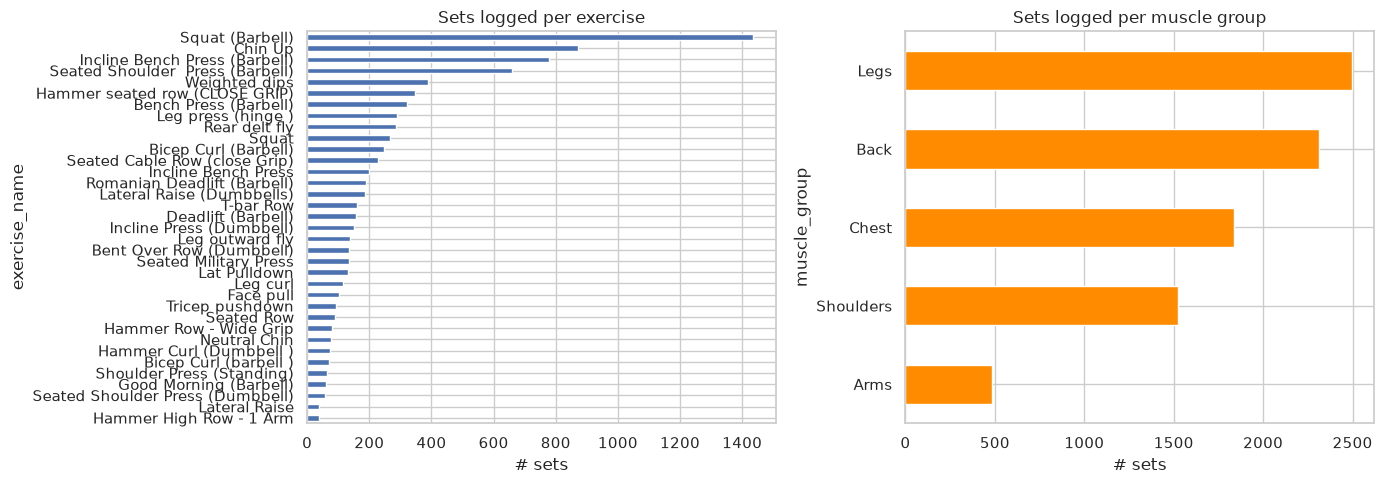

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sets_df.groupby("exercise_name").size().sort_values().plot.barh(ax=axes[0])
axes[0].set_title("Sets logged per exercise")
axes[0].set_xlabel("# sets")

sets_df.groupby("muscle_group").size().sort_values().plot.barh(ax=axes[1], color="darkorange")
axes[1].set_title("Sets logged per muscle group")
axes[1].set_xlabel("# sets")

plt.tight_layout()
fig.savefig(PLOTS_DIR / "sets_per_exercise_and_muscle_group.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Weight progression over time

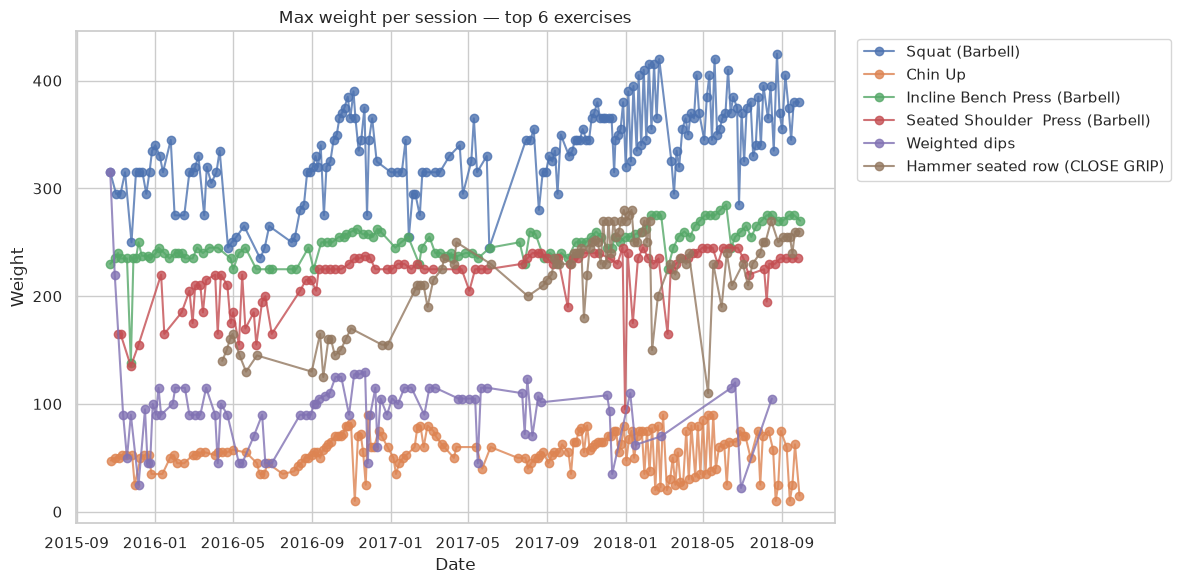

In [5]:
top_exercises = sets_df["exercise_name"].value_counts().head(6).index

fig, ax = plt.subplots(figsize=(12, 6))
for ex in top_exercises:
    sub = sets_df[sets_df["exercise_name"] == ex].groupby("date")["weight"].max().reset_index()
    ax.plot(pd.to_datetime(sub["date"]), sub["weight"], marker="o", label=ex, alpha=0.8)

ax.set_title("Max weight per session — top 6 exercises")
ax.set_xlabel("Date")
ax.set_ylabel("Weight")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
fig.savefig(PLOTS_DIR / "max_weight_top6_exercises.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Set-level distributions

The Strong export has no RPE column, so effort is described here through the
weight/rep structure instead.

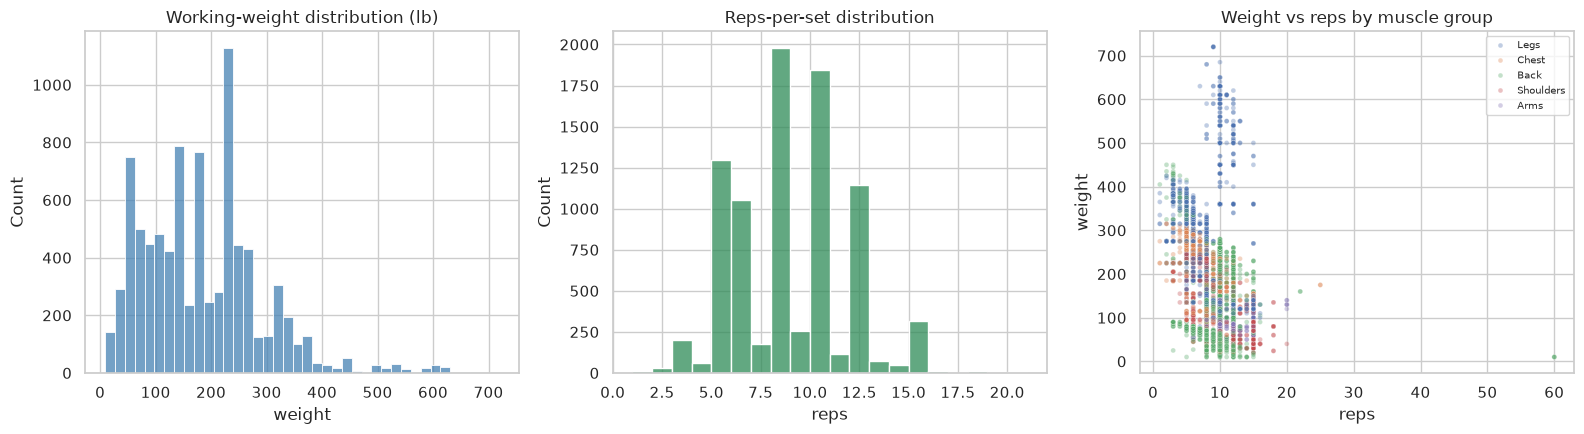

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

sns.histplot(sets_df["weight"], bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Working-weight distribution (lb)")
axes[0].set_xlabel("weight")

sns.histplot(sets_df["reps"], bins=range(1, 22), ax=axes[1], color="seagreen")
axes[1].set_title("Reps-per-set distribution")
axes[1].set_xlabel("reps")

sns.scatterplot(data=sets_df, x="reps", y="weight", hue="muscle_group",
                alpha=0.35, s=12, ax=axes[2])
axes[2].set_title("Weight vs reps by muscle group")
axes[2].legend(fontsize=7, loc="upper right")

plt.tight_layout()
fig.savefig(PLOTS_DIR / "weight_reps_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Recovery / sensor signals — not available in this dataset

The Kaggle Strong export contains no overnight HRV, resting-HR, or per-set
heart-rate data.

In [7]:
watch_features = ["hrv_rmssd_today", "resting_hr_today", "last_avg_hr", "hr_to_rpe_ratio"]
print(
    "No HRV / HR data in this export, so the four Apple-Watch features\n"
    f"  {watch_features}\n"
    "are all-NaN. SimpleImputer(strategy='median') drops all-NaN columns at fit\n"
    "time, so the model below trains on the 9 progression features that remain.\n"
    "This is the honest real-data counterpart to the synthetic seed, where those\n"
    "features were populated but carried ~0 importance."
)

No HRV / HR data in this export, so the four Apple-Watch features
  ['hrv_rmssd_today', 'resting_hr_today', 'last_avg_hr', 'hr_to_rpe_ratio']
are all-NaN. SimpleImputer(strategy='median') drops all-NaN columns at fit
time, so the model below trains on the 9 progression features that remain.
This is the honest real-data counterpart to the synthetic seed, where those
features were populated but carried ~0 importance.


## 6. Feature engineering

Rebuild the exact leave-one-out training set the production model uses
(`build_training_dataset`), so the metrics below match what `just train` produces.

**Caveats on this dataset:**

* `last_rpe` / `rpe_3s_avg` are constant 0 — the Strong export has no RPE column.
* `days_since_last` is computed as *today* minus the last session date, so on a
  2015-2018 archive it is a ~3,400-day near-constant rather than a real rest-gap
  signal. It carries near-zero importance below, so it does not distort the
  metrics, but it would only be meaningful on live data.

In [8]:
X_dicts, y = build_training_dataset(records)
X_df = pd.DataFrame(X_dicts)[FEATURE_COLS]
y_arr = np.array(y)

print(f"Training rows: {len(y_arr)}  (MIN_TRAIN_SAMPLES = {MIN_TRAIN_SAMPLES})")
X_df.describe().T

Training rows: 8616  (MIN_TRAIN_SAMPLES = 10)


,count,mean,std,min,25%,50%,75%,max
last_weight,8616.0,184.188496,108.501095,9.000000,100.000000,185.000000,245.0,720.000000
last_reps,8616.0,8.526230,3.021918,1.000000,6.000000,8.000000,10.0,60.000000
last_rpe,8616.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
days_since_last,8616.0,3440.321379,332.119549,2894.000000,3141.000000,3462.000000,3761.0,3966.000000
sessions_total,8616.0,46.542943,40.695229,1.000000,16.000000,33.000000,67.0,173.000000
weight_3s_avg,8616.0,181.394932,100.084611,17.500000,97.656250,181.666667,245.0,671.875000
rpe_3s_avg,8616.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000
reps_3s_avg,8616.0,8.526608,2.617616,2.727273,6.464286,8.237647,10.4,29.428571
target_reps,8616.0,8.524838,3.027379,1.000000,6.000000,8.000000,10.0,60.000000
hrv_rmssd_today,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


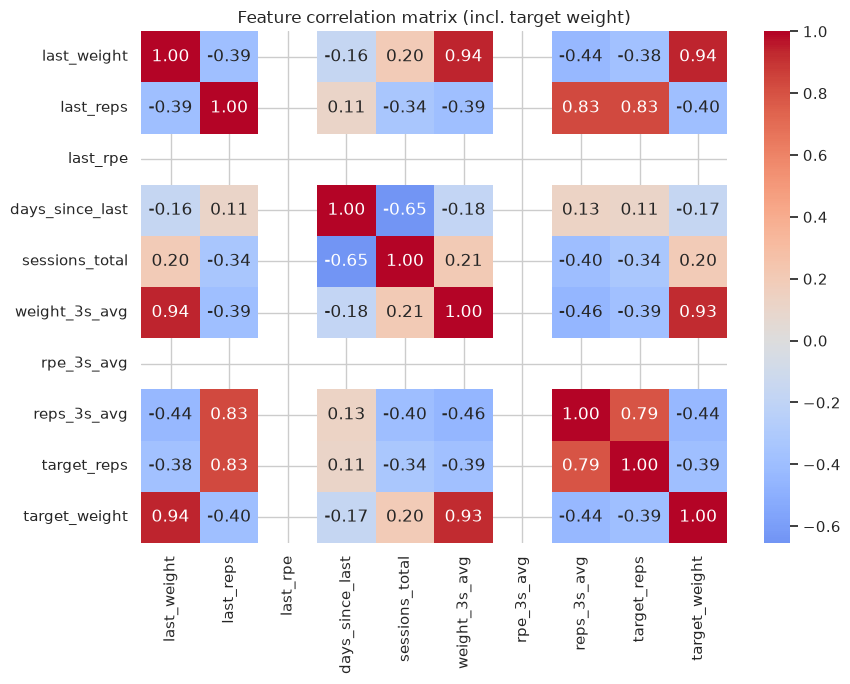

In [9]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = X_df.assign(target_weight=y_arr).dropna(axis=1, how="all").corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Feature correlation matrix (incl. target weight)")
plt.tight_layout()
fig.savefig(PLOTS_DIR / "feature_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Cross-validated model performance

In [10]:
assert len(y_arr) >= MIN_TRAIN_SAMPLES, "Not enough data for ML mode — seed more workouts first."

X = X_df.values
cv_k = min(5, max(3, len(y_arr) // 20))
kf = KFold(n_splits=cv_k, shuffle=True, random_state=42)

rmse_scores = -cross_val_score(_build_sklearn_pipeline(), X, y_arr, scoring="neg_root_mean_squared_error", cv=kf)
mae_scores  = -cross_val_score(_build_sklearn_pipeline(), X, y_arr, scoring="neg_mean_absolute_error", cv=kf)
r2_scores   =  cross_val_score(_build_sklearn_pipeline(), X, y_arr, scoring="r2", cv=kf)

metrics_df = pd.DataFrame({"RMSE": rmse_scores, "MAE": mae_scores, "R2": r2_scores})
metrics_df.index.name = f"fold (k={cv_k})"
metrics_df.loc["mean"] = metrics_df.mean()
metrics_df.loc["std"]  = metrics_df.iloc[:-1].std()
metrics_df.round(3)

,RMSE,MAE,R2
fold (k=5),,,
0,34.546,22.027,0.901
1,33.705,21.127,0.901
2,34.036,20.855,0.903
3,33.174,21.129,0.908
4,32.300,20.561,0.908
mean,33.552,21.140,0.904
std,0.860,0.548,0.003


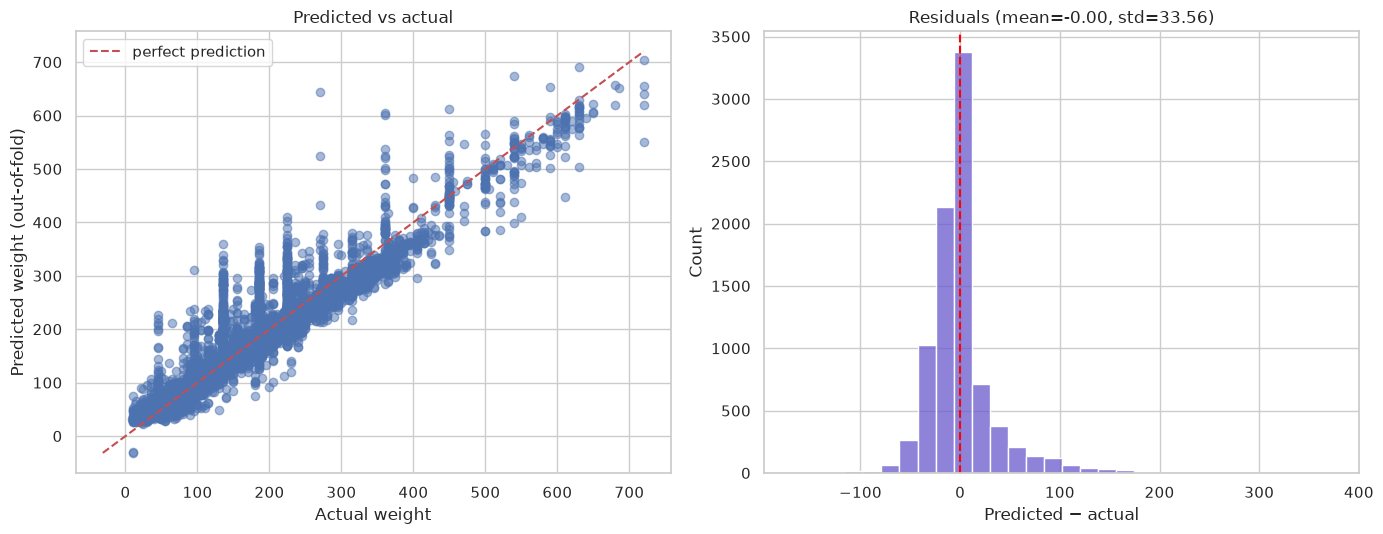

Overall CV RMSE: 33.561
Overall CV MAE:  21.140
Overall CV R2:   0.904


In [11]:
y_pred_cv = cross_val_predict(_build_sklearn_pipeline(), X, y_arr, cv=kf)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].scatter(y_arr, y_pred_cv, alpha=0.5)
lims = [min(y_arr.min(), y_pred_cv.min()), max(y_arr.max(), y_pred_cv.max())]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("Actual weight")
axes[0].set_ylabel("Predicted weight (out-of-fold)")
axes[0].set_title("Predicted vs actual")
axes[0].legend()

residuals = y_pred_cv - y_arr
sns.histplot(residuals, bins=30, ax=axes[1], color="slateblue")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title(f"Residuals (mean={residuals.mean():.2f}, std={residuals.std():.2f})")
axes[1].set_xlabel("Predicted − actual")

plt.tight_layout()
fig.savefig(PLOTS_DIR / "predicted_vs_actual_and_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Overall CV RMSE: {math.sqrt(mean_squared_error(y_arr, y_pred_cv)):.3f}")
print(f"Overall CV MAE:  {mean_absolute_error(y_arr, y_pred_cv):.3f}")
print(f"Overall CV R2:   {r2_score(y_arr, y_pred_cv):.3f}")

## 8. Feature importance (GradientBoosting sub-model)

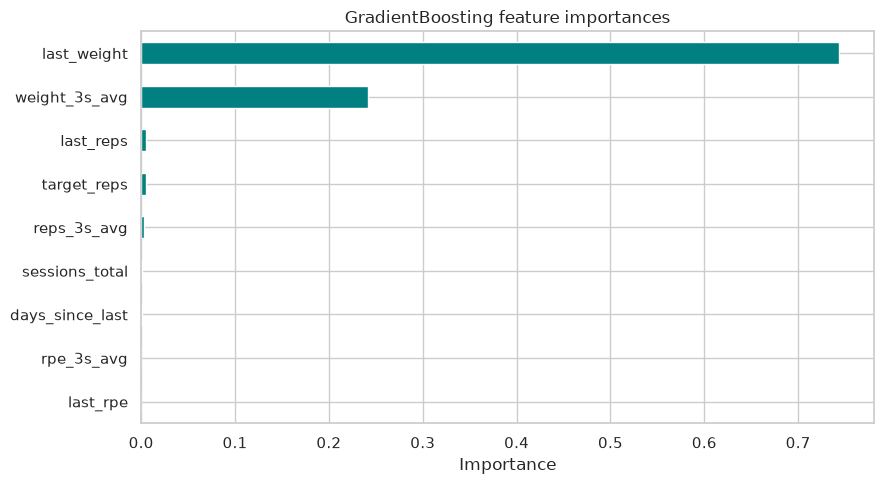

In [12]:
full_pipeline = _build_sklearn_pipeline()
full_pipeline.fit(X, y_arr)

# SimpleImputer drops all-NaN columns (the watch features), so realign names.
imp_stats = full_pipeline.named_steps["impute"].statistics_
kept_cols = [c for c, ok in zip(FEATURE_COLS, ~np.isnan(imp_stats)) if ok]

gbr = full_pipeline.named_steps["model"].estimators_[1]  # ("gbr", GradientBoostingRegressor)
importances = pd.Series(gbr.feature_importances_, index=kept_cols).sort_values()

fig, ax = plt.subplots(figsize=(9, 5))
importances.plot.barh(ax=ax, color="teal")
ax.set_title("GradientBoosting feature importances")
ax.set_xlabel("Importance")
plt.tight_layout()
fig.savefig(PLOTS_DIR / "gbr_feature_importances.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Ridge vs GradientBoosting — sub-model agreement

The production confidence score is derived from how much the two sub-estimators
in the `VotingRegressor` disagree, normalised by CV RMSE (see
`ProgressionPredictor._ensemble_confidence`).

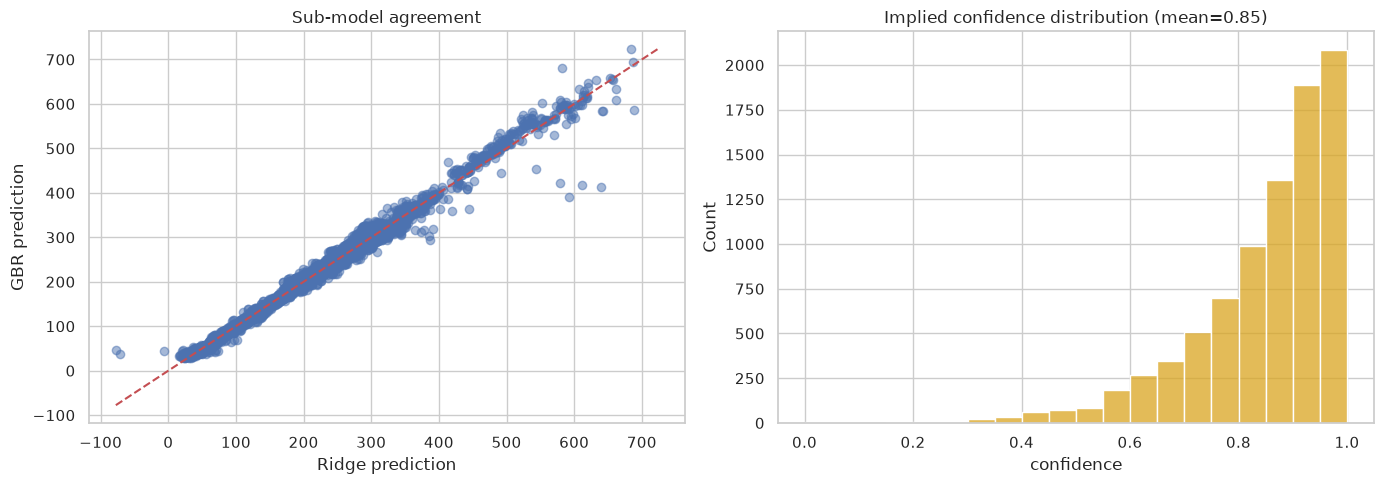

In [13]:
ridge_pred = full_pipeline.named_steps["model"].estimators_[0].predict(
    full_pipeline.named_steps["scale"].transform(full_pipeline.named_steps["impute"].transform(X))
)
gbr_pred = full_pipeline.named_steps["model"].estimators_[1].predict(
    full_pipeline.named_steps["scale"].transform(full_pipeline.named_steps["impute"].transform(X))
)

cv_rmse = metrics_df.loc["mean", "RMSE"]
disagreement = np.abs(ridge_pred - gbr_pred)
confidence = np.exp(-disagreement / cv_rmse)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(ridge_pred, gbr_pred, alpha=0.5)
lims = [min(ridge_pred.min(), gbr_pred.min()), max(ridge_pred.max(), gbr_pred.max())]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Ridge prediction")
axes[0].set_ylabel("GBR prediction")
axes[0].set_title("Sub-model agreement")

sns.histplot(confidence, bins=20, ax=axes[1], color="goldenrod")
axes[1].set_title(f"Implied confidence distribution (mean={confidence.mean():.2f})")
axes[1].set_xlabel("confidence")

plt.tight_layout()
fig.savefig(PLOTS_DIR / "submodel_agreement_and_confidence.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Per-exercise error breakdown

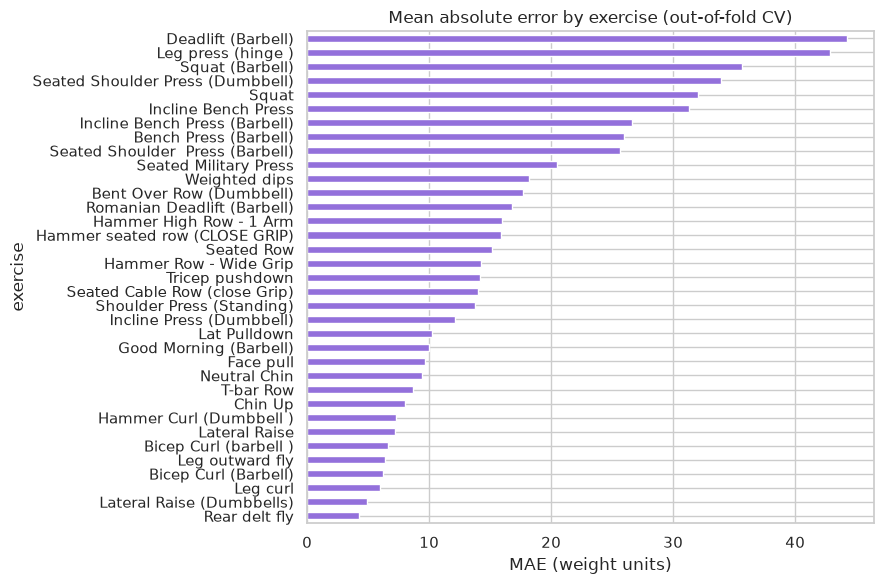

,mean,count
exercise,,
Rear delt fly,4.21,284
Lateral Raise (Dumbbells),4.91,185
Leg curl,5.99,115
Bicep Curl (Barbell),6.20,246
Leg outward fly,6.36,136
Bicep Curl (barbell ),6.61,68
Lateral Raise,7.18,37
Hammer Curl (Dumbbell ),7.32,73
Chin Up,7.99,871


In [14]:
ex_names = [str(r.get("exercise_name") or "") for r in records if r.get("weight") is not None]
# align exercise names to X/y rows: build_training_dataset iterates per-exercise in insertion
# order, so recompute alongside to keep indices in sync.
from app.ml.features import build_training_dataset as _btd

by_exercise = {}
for r in records:
    ex = str(r.get("exercise_name") or "")
    if ex:
        by_exercise.setdefault(ex, []).append(r)

row_exercise = []
for ex, recs in by_exercise.items():
    recs_sorted = sorted(recs, key=lambda r: (str(r.get("date") or ""), int(r.get("set_order") or 0)))
    for i, rec in enumerate(recs_sorted):
        if rec.get("weight") is None or i == 0:
            continue
        row_exercise.append(ex)

err_df = pd.DataFrame({"exercise": row_exercise, "actual": y_arr, "predicted": y_pred_cv})
err_df["abs_error"] = (err_df["predicted"] - err_df["actual"]).abs()

per_ex = err_df.groupby("exercise")["abs_error"].agg(["mean", "count"]).sort_values("mean")

fig, ax = plt.subplots(figsize=(9, 6))
per_ex["mean"].plot.barh(ax=ax, color="mediumpurple")
ax.set_title("Mean absolute error by exercise (out-of-fold CV)")
ax.set_xlabel("MAE (weight units)")
plt.tight_layout()
fig.savefig(PLOTS_DIR / "mae_by_exercise.png", dpi=150, bbox_inches="tight")
plt.show()

per_ex.round(2)

## 11. Summary

Quick reference of the headline numbers computed above.

In [15]:
summary = {
    "training_rows": len(y_arr),
    "cv_folds": cv_k,
    "cv_rmse": round(metrics_df.loc["mean", "RMSE"], 3),
    "cv_mae": round(metrics_df.loc["mean", "MAE"], 3),
    "cv_r2": round(metrics_df.loc["mean", "R2"], 3),
    "mean_confidence": round(float(confidence.mean()), 3),
}
pd.Series(summary)

training_rows      8616.000
cv_folds              5.000
cv_rmse              33.552
cv_mae               21.140
cv_r2                 0.904
mean_confidence       0.851
dtype: float64